# Credit Card Fraud Detection — EDA

**Goal:** Understand the dataset before modeling.
**Problem:** Binary classification (fraud = 1, legit = 0) on highly imbalanced data.

**Dataset:** 284,807 transactions from European cardholders (Sept 2013).
- Features `V1`-`V28`: PCA-transformed (anonymized)
- `Time`: seconds since first transaction
- `Amount`: transaction amount
- `Class`: target label (0 = legit, 1 = fraud)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#plot design
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

#show all columns 
pd.set_option('display.max_columns', None)

print("Imports OK")



Imports OK


In [2]:
df = pd.read_csv('../data/creditcard.csv')
print(f"Shape: {df.shape}")
df.head()


Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100

print("Class Distribution:")
print(f"Legit (0): {class_counts[0]:,} ({class_pct[0]:.3f}%)")
print(f"Fraud (1): {class_counts[1]:,} ({class_pct[1]:.3f}%)") 

print(f"\nImbalance Ratio (Legit:Fraud): {class_counts[0] / class_counts[1]:.0f} : 1")

# What a accuracy would a "predict everything is legit" model get?
baseline_acc = class_pct[0]
print(f"\n A dumb model that always says 'legit' scores: {baseline_acc:.2f}% accuracy")
print("   ...but catches ZERO fraud. This is why accuracy is a poor metric for imbalanced datasets.")



Class Distribution:
Legit (0): 284,315 (99.827%)
Fraud (1): 492 (0.173%)

Imbalance Ratio (Legit:Fraud): 578 : 1

 A dumb model that always says 'legit' scores: 99.83% accuracy
   ...but catches ZERO fraud. This is why accuracy is a poor metric for imbalanced datasets.


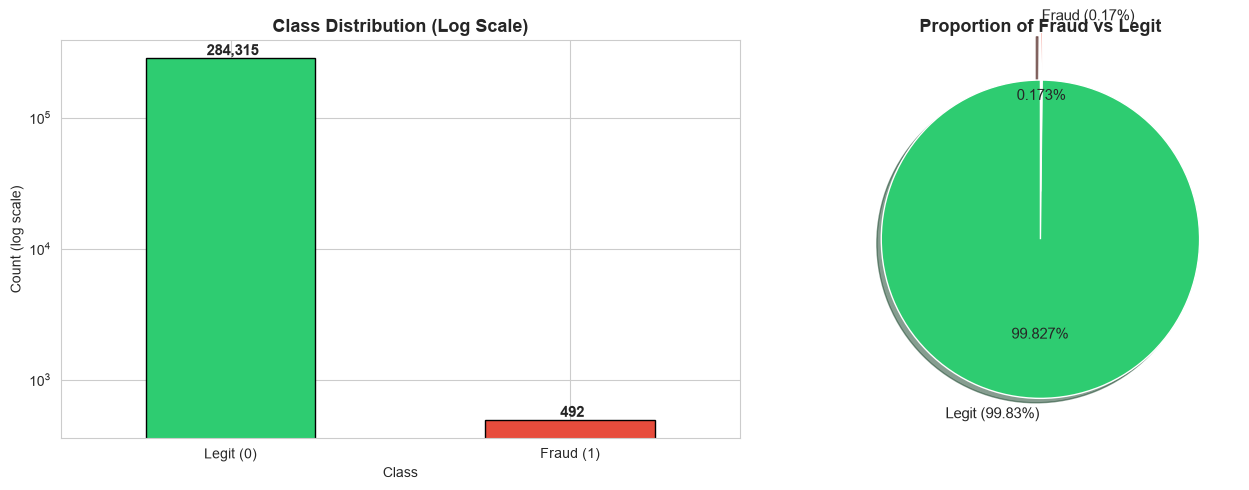

Chart saved to data/class_imbalance.png — you'll use this in the README later.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left: Bar chart (log scale so fraud bar is visible) ---
class_counts.plot(kind="bar", ax=axes[0], color=["#2ecc71", "#e74c3c"], edgecolor="black")
axes[0].set_title("Class Distribution (Log Scale)", fontsize=13, fontweight="bold")
axes[0].set_yscale("log")
axes[0].set_xticklabels(["Legit (0)", "Fraud (1)"], rotation=0)
axes[0].set_ylabel("Count (log scale)")
axes[0].set_xlabel("Class")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v, f" {v:,}", ha="center", va="bottom", fontsize=11, fontweight="bold")

# --- Right: Pie chart showing the actual proportion ---
axes[1].pie(
    class_counts,
    labels=["Legit (99.83%)", "Fraud (0.17%)"],
    autopct="%1.3f%%",
    colors=["#2ecc71", "#e74c3c"],
    startangle=90,
    explode=(0, 0.3),  # pop out the fraud slice
    shadow=True,
    textprops={"fontsize": 11}
)
axes[1].set_title("Proportion of Fraud vs Legit", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("../data/class_imbalance.png", dpi=100, bbox_inches="tight")
plt.show()

print("Chart saved to data/class_imbalance.png — you'll use this in the README later.")

In [6]:
# Raw counts
counts = df["Class"].value_counts()
print("Raw counts:")
print(counts)
print()

# Fractions
fractions = df["Class"].value_counts(normalize=True)
print("Fractions:")
print(fractions)
print()

# Percentages
percs = df["Class"].value_counts(normalize=True) * 100
print("Percentages:")
print(percs)
print()

# Verify the math manually
total = len(df)
print(f"Total rows: {total}")
print(f"Manual check: {counts[1]} / {total} = {counts[1] / total:.5f}")
print(f"As percentage: {(counts[1] / total * 100):.3f}%")

Raw counts:
Class
0    284315
1       492
Name: count, dtype: int64

Fractions:
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

Percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Total rows: 284807
Manual check: 492 / 284807 = 0.00173
As percentage: 0.173%


### Finding #1: Extreme Class Imbalance

- Legit transactions: 284,315 (99.827%)
- Fraud transactions: 492 (0.173%)
- Ratio: ~578:1

**Consequences for modeling:**
1. Accuracy is useless — the majority-class baseline is 99.83%
2. Must use precision, recall, F1, and AUPRC
3. Need class weighting or resampling (SMOTE) during training
4. Decision threshold should be tuned, not left at 0.5

In [7]:
# Split amount by class
legit_amounts = df[df["Class"]==0 ]["Amount"]
fraud_amounts = df[df["Class"]==1 ]["Amount"]

print("=== AMOUNT STATISTICS ===")
print(f"Legit (n={len(legit_amounts):,}):")
print(f"  Mean: {legit_amounts.mean():.2f}")
print(f"  Median: {legit_amounts.median():.2f}")
print(f"  Max: {legit_amounts.max():.2f}")
print(f"  Min: {legit_amounts.min():.2f}")

print(f"\nFraud (n={len(fraud_amounts):,}):")
print(f"  Mean: {fraud_amounts.mean():.2f}")
print(f"  Median: {fraud_amounts.median():.2f}")
print(f"  Max: {fraud_amounts.max():.2f}")
print(f"  Min: {fraud_amounts.min():.2f}")


=== AMOUNT STATISTICS ===
Legit (n=284,315):
  Mean: 88.29
  Median: 22.00
  Max: 25691.16
  Min: 0.00

Fraud (n=492):
  Mean: 122.21
  Median: 9.25
  Max: 2125.87
  Min: 0.00


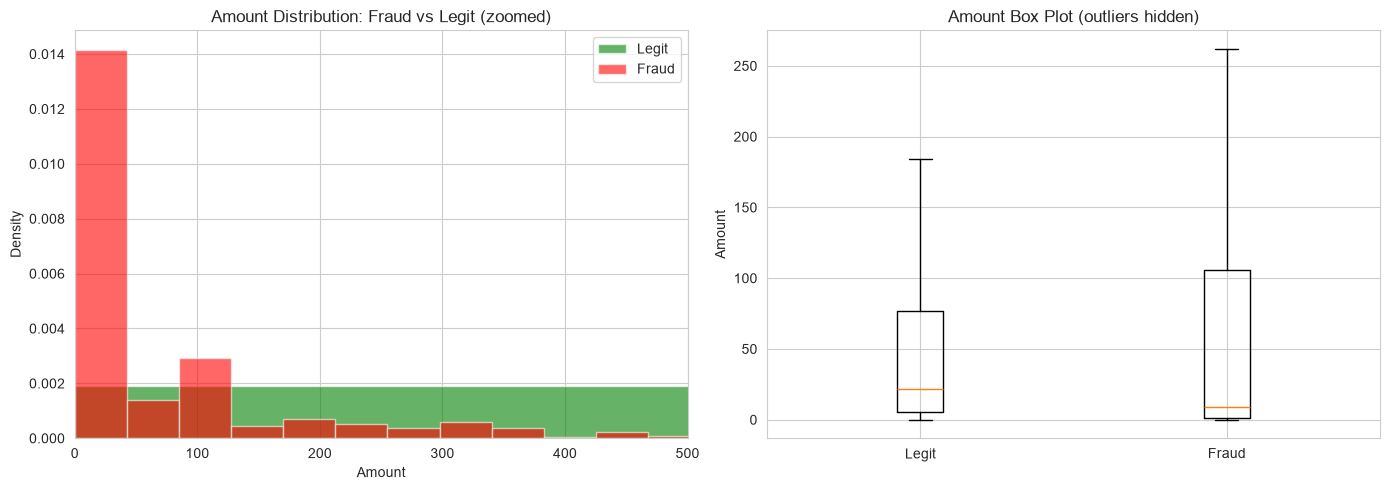

Saved to data/amount_distribution.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Histogram comparing distributions
axes[0].hist(legit_amounts, bins=50, alpha=0.6, label="Legit", color="green", density=True)
axes[0].hist(fraud_amounts, bins=50, alpha=0.6, label="Fraud", color="red", density=True)
axes[0].set_xlim(0, 500)  # zoom in (most transactions are small)
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Density")
axes[0].set_title("Amount Distribution: Fraud vs Legit (zoomed)")
axes[0].legend()

# Right: Box plot for direct comparison
axes[1].boxplot([legit_amounts, fraud_amounts], tick_labels=["Legit", "Fraud"], showfliers=False)
axes[1].set_ylabel("Amount")
axes[1].set_title("Amount Box Plot (outliers hidden)")

plt.tight_layout()
plt.savefig("../data/amount_distribution.png", dpi=100, bbox_inches="tight")
plt.show()

print("Saved to data/amount_distribution.png")

### Finding #2: Amount Distribution Differs by Class

- **Legit transactions**: median ~22, mean ~88
- **Fraud transactions**: median ~9, mean ~122

**Key observations:**
1. **Fraud has a lower median** — the typical fraud is a *small* transaction
2. **Fraud has a higher mean** — a few large frauds pull the average up
3. **Fraud peaks sharply near 0** — most frauds are small amounts
4. **Fraud rarely exceeds 500** — big transactions are likely already flagged by other rules

**Consequences for modeling:**
- `Amount` is a **useful feature** — the classes have visibly different distributions
- `Amount` is **heavily right-skewed** → we'll need to scale it (log transform or StandardScaler)
- Combining `Amount` with `Time` and `V` features should improve prediction

In [9]:
# Convert Time (seconds) to hour of day (0-23)
df["Hour"] = (df["Time"] / 3600) % 24

print("Time column range:", df["Time"].min(), "to", df["Time"].max())
print("Hour range:", df["Hour"].min(), "to", df["Hour"].max())
print()
print("Sample:")
print(df[["Time", "Hour", "Class"]].head(10))

Time column range: 0.0 to 172792.0
Hour range: 0.0 to 23.999444444444446

Sample:
   Time      Hour  Class
0   0.0  0.000000      0
1   0.0  0.000000      0
2   1.0  0.000278      0
3   1.0  0.000278      0
4   2.0  0.000556      0
5   2.0  0.000556      0
6   4.0  0.001111      0
7   7.0  0.001944      0
8   7.0  0.001944      0
9   9.0  0.002500      0


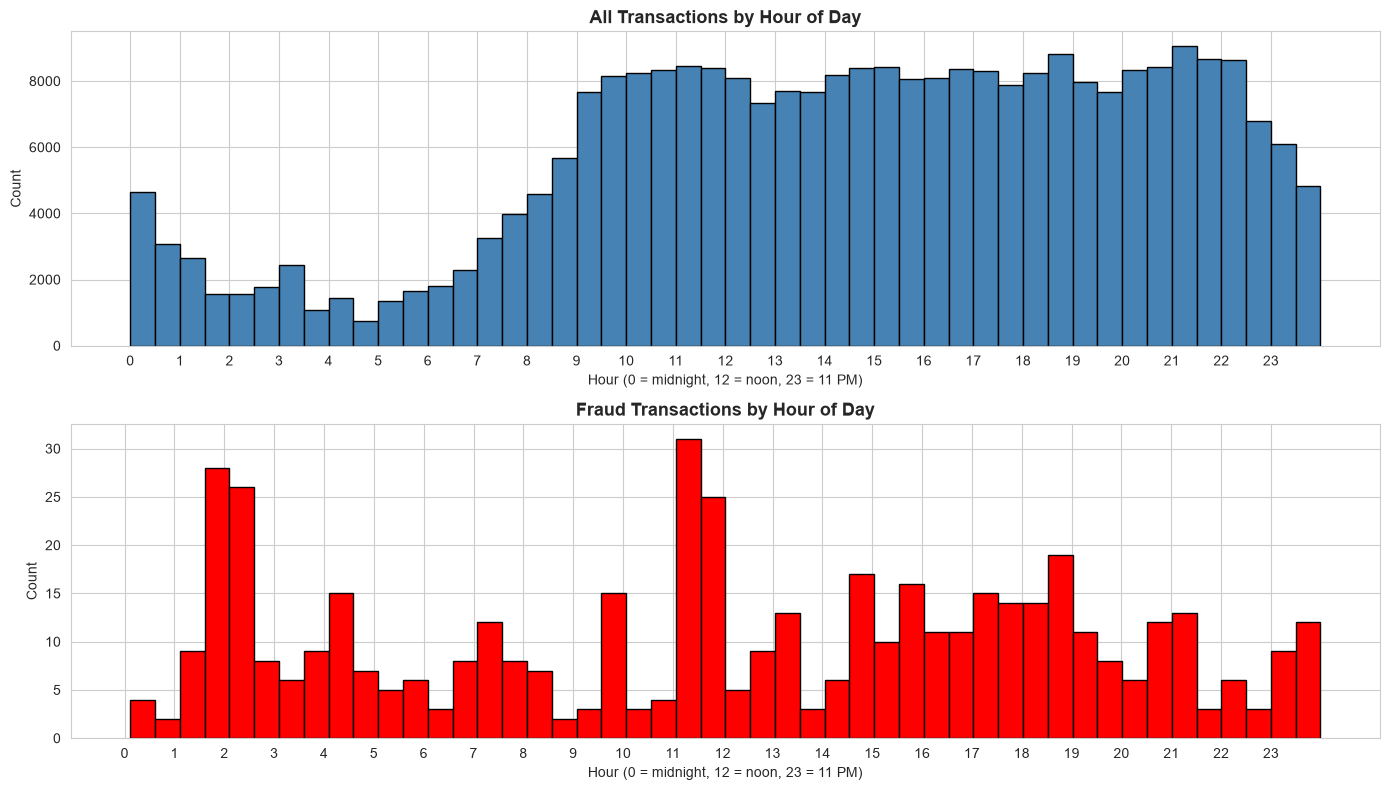

Saved to data/time_patterns.png


In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Top: ALL transactions by hour
axes[0].hist(df["Hour"], bins=48, color="steelblue", edgecolor="black")
axes[0].set_title("All Transactions by Hour of Day", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Hour (0 = midnight, 12 = noon, 23 = 11 PM)")
axes[0].set_ylabel("Count")
axes[0].set_xticks(range(0, 24))

# Bottom: FRAUD ONLY transactions by hour
axes[1].hist(df[df["Class"] == 1]["Hour"], bins=48, color="red", edgecolor="black")
axes[1].set_title("Fraud Transactions by Hour of Day", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Hour (0 = midnight, 12 = noon, 23 = 11 PM)")
axes[1].set_ylabel("Count")
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.savefig("../data/time_patterns.png", dpi=100, bbox_inches="tight")
plt.show()
print("Saved to data/time_patterns.png")

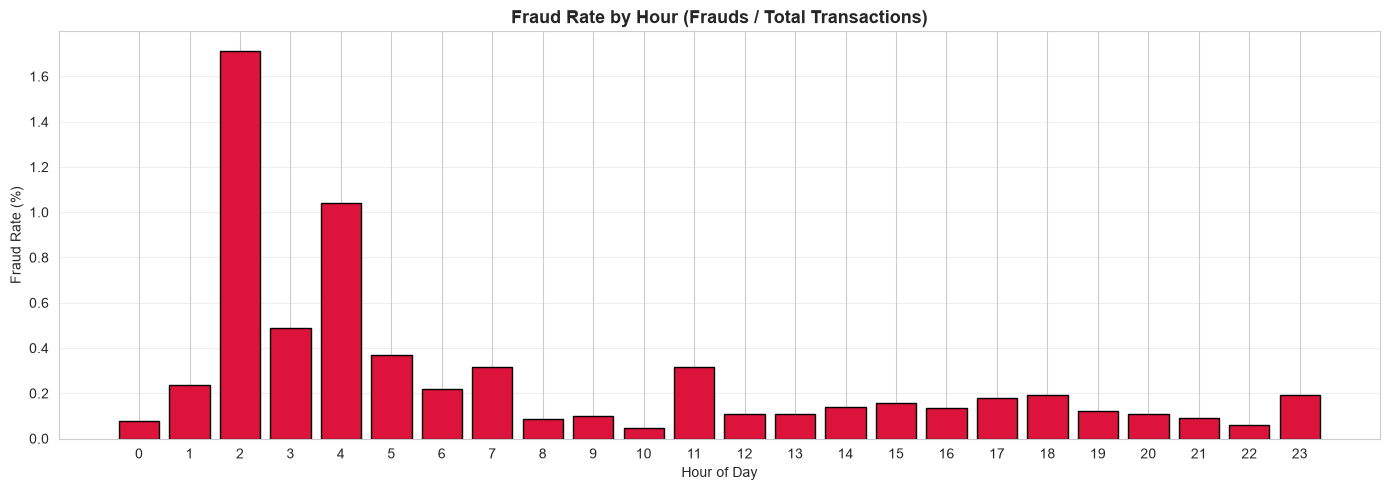


Top 5 hours with highest fraud rate:
      total  frauds  fraud_rate_%
Hour                             
2      3328      57      1.712740
4      2209      23      1.041195
3      3492      17      0.486827
5      2990      11      0.367893
7      7243      23      0.317548

Overall fraud rate: 0.173%


In [11]:
# Compute fraud rate per hour
hourly = df.groupby(df["Hour"].astype(int)).agg(
    total=("Class", "count"),
    frauds=("Class", "sum")
)
hourly["fraud_rate_%"] = (hourly["frauds"] / hourly["total"]) * 100

# Plot
fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(hourly.index, hourly["fraud_rate_%"], color="crimson", edgecolor="black")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Rate by Hour (Frauds / Total Transactions)", fontsize=13, fontweight="bold")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../data/fraud_rate_by_hour.png", dpi=100, bbox_inches="tight")
plt.show()

# Top 5 dangerous hours
print("\nTop 5 hours with highest fraud rate:")
print(hourly.nlargest(5, "fraud_rate_%")[["total", "frauds", "fraud_rate_%"]])

# Overall average fraud rate
print(f"\nOverall fraud rate: {df['Class'].mean() * 100:.3f}%")

### Finding #3: Fraud Concentrates at Night Hours (Confirmed)

**Top 5 highest fraud-rate hours:**
| Hour | Total | Frauds | Fraud Rate |
|------|-------|--------|------------|
| 2 AM | 3,328 | 57 | 1.71% |
| 4 AM | 2,209 | 23 | 1.04% |
| 3 AM | 3,492 | 17 | 0.49% |
| 5 AM | 2,990 | 11 | 0.37% |
| 7 AM | 7,243 | 23 | 0.32% |

**Overall fraud rate: 0.173%**

**Key observation:** Hour 2 AM has a fraud rate of **1.71%** — nearly **10× the overall average**. Between 2-4 AM, roughly 1 in 60 transactions is fraud; during daytime hours, it's closer to 1 in 1,000.

**Interpretation:**
- Fraudsters target hours when cardholders are asleep (won't notice unauthorized charges)
- Bank monitoring staff are fewer at night, so automated rules are the only defense
- The **rate** (not raw count) reveals the pattern — daytime has more frauds in absolute terms, but far more legit transactions too

**Consequences for modeling:**
1. `Hour` is a **strong engineered feature** — extract it from `Time` during preprocessing
2. `Time` itself should also be kept (converted to hours, and possibly day-of-week)
3. The model will learn this pattern automatically from the `Hour` feature

In [12]:
# Correlation of every feature with the target (Class)
correlations = df.corr(numeric_only=True)["Class"].drop("Class")

# Sort by absolute value (strongest signal first)
top_corr = correlations.abs().sort_values(ascending=False)

print("Top 15 features by absolute correlation with Class:")
print()
for feat, val in top_corr.head(15).items():
    sign = "+" if correlations[feat] > 0 else "-"
    print(f"  {feat:<8} {sign}{val:.4f}")

Top 15 features by absolute correlation with Class:

  V17      -0.3265
  V14      -0.3025
  V12      -0.2606
  V10      -0.2169
  V16      -0.1965
  V3       -0.1930
  V7       -0.1873
  V11      +0.1549
  V4       +0.1334
  V18      -0.1115
  V1       -0.1013
  V9       -0.0977
  V5       -0.0950
  V2       +0.0913
  V6       -0.0436


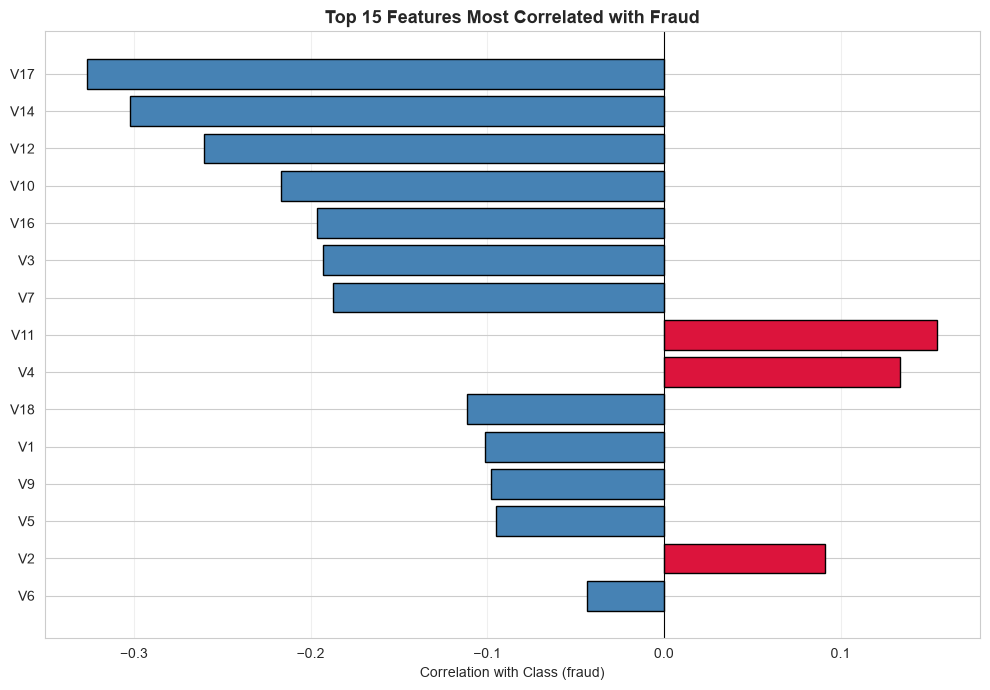

Saved to data/top_features_correlation.png


In [13]:
# Bar chart of top 15 by absolute correlation
top_15 = top_corr.head(15).sort_values()
top_15_signed = correlations[top_15.index]

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["crimson" if v > 0 else "steelblue" for v in top_15_signed.values]
ax.barh(top_15_signed.index, top_15_signed.values, color=colors, edgecolor="black")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with Class (fraud)")
ax.set_title("Top 15 Features Most Correlated with Fraud", fontsize=13, fontweight="bold")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("../data/top_features_correlation.png", dpi=100, bbox_inches="tight")
plt.show()
print("Saved to data/top_features_correlation.png")

### Finding #4: Top Discriminative Features (V17, V14, V12, V10)

**Top V-features by absolute correlation with fraud:**
| Feature | Correlation | Direction |
|---------|-------------|-----------|
| V17 | -0.3265 | Lower V17 → more likely fraud |
| V14 | -0.3025 | Lower V14 → more likely fraud |
| V12 | -0.2606 | Lower V12 → more likely fraud |
| V10 | -0.2169 | Lower V10 → more likely fraud |
| V16 | -0.1965 | Lower V16 → more likely fraud |

**Key observations:**
1. **No single feature is decisive** — max |correlation| is only 0.33
2. **V17, V14, V12, V10** are the strongest signals — all negative correlations
3. **Positive correlations exist** (V11, V4) but are weaker
4. Most V-features have very weak correlations (< 0.1) — they contribute little individually

**Why low correlations are expected:**
- PCA distributes the fraud signal across many components
- Fraud is fundamentally a **multivariate** problem — no single feature tells the whole story
- Tree-based models (like XGBoost) can find **nonlinear combinations** that correlation can't detect

**Consequences for modeling:**
1. Keep all V-features initially — the model will decide which to use
2. **Feature importance** from the trained model will be more informative than correlation (we'll do this in Phase 3)
3. Don't drop V-features based on correlation alone — many contribute through interactions

In [14]:
print("correlations (feature-to-Class correlations):")
print(correlations.head())
print()
print("Data type:", correlations.dtype)
print("Min value:", correlations.min())
print("Max value:", correlations.max())

correlations (feature-to-Class correlations):
Time   -0.012323
V1     -0.101347
V2      0.091289
V3     -0.192961
V4      0.133447
Name: Class, dtype: float64

Data type: float64
Min value: -0.32648106724371595
Max value: 0.15487564474394433


In [15]:
print("\nOriginal df['Class']:")
print(df["Class"].head())
print("\nUnique values in df['Class']:", df["Class"].unique())


Original df['Class']:
0    0
1    0
2    0
3    0
4    0
Name: Class, dtype: int64

Unique values in df['Class']: [0 1]


In [16]:
print("Top 10 features by absolute correlation with Class:")
print()
print(correlations.abs().sort_values(ascending=False).head(10))

Top 10 features by absolute correlation with Class:

V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
Name: Class, dtype: float64


### Finding #4: Top Discriminative Features

**Top 10 features by absolute correlation with fraud:**

| Rank | Feature | Correlation | Direction |
|------|---------|-------------|-----------|
| 1 | V17 | 0.3265 | Lower → fraud |
| 2 | V14 | 0.3025 | Lower → fraud |
| 3 | V12 | 0.2606 | Lower → fraud |
| 4 | V10 | 0.2169 | Lower → fraud |
| 5 | V16 | 0.1965 | Lower → fraud |
| 6 | V3 | 0.1930 | Lower → fraud |
| 7 | V7 | 0.1873 | Lower → fraud |
| 8 | V11 | 0.1549 | Higher → fraud |
| 9 | V4 | 0.1334 | Higher → fraud |
| 10 | V18 | 0.1115 | Lower → fraud |

**Interpretation:**
- **No single feature is decisive** — max correlation is only 0.33
- **V17, V14, V12, V10** carry the strongest individual signals
- **Most strong signals are negative** — low values in these features → higher fraud probability
- **V11 and V4 are positive signals** — higher values → higher fraud probability
- **Weak individual signals** are expected in fraud detection; the model will combine them

**Consequences for modeling:**
1. Keep all V-features initially — XGBoost will rank them by actual usefulness
2. **Feature importance** after training will be more informative than correlation
3. The combination of weak signals (V-features + Hour + Amount) is what makes the model powerful

# EDA Summary — Key Findings

We explored the credit card fraud dataset (284,807 transactions, 31 columns). Here are the findings that will drive our modeling decisions:

## Finding #1: Extreme Class Imbalance
- Legit: 284,315 (99.827%)
- Fraud: 492 (0.173%)
- Ratio: 578:1
- **Impact:** Accuracy is useless. Use precision, recall, F1, and AUPRC.

## Finding #2: Amount Distribution Differs by Class
- Legit: median ~€22, mean ~€88
- Fraud: median ~€9, mean ~€122
- **Impact:** `Amount` is a useful but weak signal. Needs scaling (heavy right skew).

## Finding #3: Fraud Concentrates at Night Hours
- Hour 2 AM has fraud rate 1.71% — ~10× the overall average (0.173%)
- Hours 2-4 AM are the most dangerous
- **Impact:** Extract `Hour` from `Time` as an engineered feature.

## Finding #4: Top Discriminative Features
- Strongest: V17 (0.327), V14 (0.303), V12 (0.261), V10 (0.217)
- All correlations are weak (max 0.33) — no single decisive feature
- **Impact:** Keep all V-features; rely on XGBoost to find nonlinear combinations.

## Data Quality
- No missing values
- All numeric (V1-V28 are PCA-transformed, uninterpretable)
- Time spans ~48 hours

## Preprocessing Decisions for Phase 2
1. **Split:** Stratified train/test to preserve the 0.173% fraud rate
2. **Engineer:** `Hour` from `Time` (drop raw Time or keep both)
3. **Scale:** `Amount` (log transform or StandardScaler)
4. **Handle imbalance:** Use `scale_pos_weight` in XGBoost (start simple; consider SMOTE later)
5. **Metric:** Focus on AUPRC, precision, recall — never accuracy

## Next Step
Move from notebook exploration to reusable scripts in `src/preprocess.py` and `src/train.py`.